In [ ]:
import os

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     cross_validate, permutation_test_score)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (make_scorer, accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix)

RANDOM_STATE = 42     # makes every split, fold and forest reproducible
FAIL_MARK = 50        # a mark below this is a fail
TEST_SIZE = 0.30      # 70% train / 30% test

sns.set_style('whitegrid')

# 2. Load the data

In [ ]:
from google.colab import files
uploaded = files.upload()
df=pd.read_excel("df_final.xlsx")
df.head()

Saving df_final.xlsx to df_final.xlsx


,Student_ID,Academic Year,APPLIED MECHANICS,COMPUTER SKILLS,CONSTRUCTION MATERIALS TECHNOLOGY,ENGINEERING CHEMISTRY,ENGINEERING DRAWING 1,ENGINEERING MATHEMATICS 1,ENGINEERING PHYSICS,PROFESSIONAL AND TECHNICAL COMMUNICATION,...,Language Name,Ethnic Group Name,Previous Activity Desc,Matric Type,Age_At_Enrolment,Bursary Type,Funded,Residence_Status,At_Risk_Status,Secondary_School_Quintile
0,ebad61ae15967effac440603214e2e829bb29399e52236...,2022,80,76,67,77,67,62,50,58,...,ISIZULU,AFRICAN,UNEMPLOYED,B,19,NSFAS,Yes,Yes,No,3
1,f521b30f9daaa32d07004bfe337461cbe32083db1a4c4f...,2022,68,42,62,72,65,66,55,63,...,XHOSA,AFRICAN,OTHER,B,19,NSFAS,Yes,No,Yes,2
2,a39ac7e2e46a3c504ea680c833542b44509590f9566861...,2022,50,59,63,69,73,51,50,62,...,XHOSA,AFRICAN,GRADE12 LEARNER,B,20,NSFAS,Yes,Yes,No,5
3,32d8a74e94211a616b9c701f62ebf8ef4a90162ab430a6...,2022,56,62,62,75,55,50,53,57,...,XHOSA,AFRICAN,GRADE12 LEARNER,B,20,NSFAS,Yes,Yes,Yes,1
4,d5aa2443cbcb70dfffa1a66fcbcf4bca0953a2d8d55e39...,2022,64,66,71,78,53,69,56,59,...,XHOSA,AFRICAN,OTHER,B,19,NSFAS,Yes,No,No,3


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 330 entries, 0 to 329
Data columns (total 23 columns):
 #   Column                                    Non-Null Count  Dtype 
---  ------                                    --------------  ----- 
 0   Student_ID                                330 non-null    object
 1   Academic Year                             330 non-null    int64 
 2   APPLIED MECHANICS                         330 non-null    int64 
 3   COMPUTER SKILLS                           330 non-null    int64 
 4   CONSTRUCTION MATERIALS TECHNOLOGY         330 non-null    int64 
 5   ENGINEERING CHEMISTRY                     330 non-null    int64 
 6   ENGINEERING DRAWING 1                     330 non-null    int64 
 7   ENGINEERING MATHEMATICS 1                 330 non-null    int64 
 8   ENGINEERING PHYSICS                       330 non-null    int64 
 9   PROFESSIONAL AND TECHNICAL COMMUNICATION  330 non-null    int64 
 10  SURVEYING                                 330 non-

# 3. Prepare the data for modelling

In [ ]:
rename_map = {
    'APPLIED MECHANICS': 'Applied Mechanics', 'COMPUTER SKILLS': 'Computer Skills',
    'CONSTRUCTION MATERIALS TECHNOLOGY': 'Construction Materials', 'ENGINEERING CHEMISTRY': 'Engineering Chemistry',
    'ENGINEERING DRAWING 1': 'Engineering Drawing 1', 'ENGINEERING MATHEMATICS 1': 'Engineering Mathematics 1',
    'ENGINEERING PHYSICS': 'Engineering Physics', 'PROFESSIONAL AND TECHNICAL COMMUNICATION': 'Professional Communication',
    'SURVEYING': 'Surveying', 'THEORY OF STRUCTURES': 'Theory of Structures',
    'Language Name': 'Home Language', 'Ethnic Group Name': 'Ethnic Group', 'Previous Activity Desc': 'Previous Activity',
    'Age_At_Enrolment': 'Age at Enrolment', 'Residence_Status': 'In Residence',
    'Secondary_School_Quintile': 'School Quintile', 'At_Risk_Status': 'At Risk',
}
subject_cols = ['Applied Mechanics', 'Computer Skills', 'Construction Materials', 'Engineering Chemistry',
                'Engineering Drawing 1', 'Engineering Mathematics 1', 'Engineering Physics',
                'Professional Communication', 'Surveying', 'Theory of Structures']

df.columns = df.columns.astype(str).str.strip()
df1 = df.drop(columns=['Student_ID'], errors='ignore').rename(columns=rename_map)   # the ID carries no information

# Keep only students with all ten subject marks
df1[subject_cols] = df1[subject_cols].apply(pd.to_numeric, errors='coerce')
n_before = len(df1)
df1 = df1.dropna(subset=subject_cols).reset_index(drop=True)
print(f'Students removed for missing subject marks: {n_before - len(df1)} | kept: {len(df1)}')

Students removed for missing subject marks: 0 | kept: 330


In [ ]:
# Consistent labels
yes_no = {1: 'Yes', 0: 'No', 'Yes': 'Yes', 'No': 'No', 'Y': 'Yes', 'N': 'No'}
for col in ['Funded', 'In Residence', 'At Risk']:
    df1[col] = df1[col].map(yes_no)
assert df1['At Risk'].notna().all(), 'At Risk has values other than Yes/No'
df1['Gender'] = df1['Gender'].replace({'F': 'Female', 'M': 'Male'})

# Numeric target: 1 = at risk, 0 = not at risk
y = df1['At Risk'].map({'Yes': 1, 'No': 0})

In [ ]:
# Class balance of the target
class_counts = y.value_counts().rename({0: 'Not at risk', 1: 'At risk'})
display(pd.DataFrame({'Students': class_counts, 'Share (%)': (class_counts / len(y) * 100).round(1)}))

,Students,Share (%)
At Risk,,
Not at risk,209,63.3
At risk,121,36.7


# 4. Define the feature sets

In [ ]:
background = ['Gender', 'Home Language', 'Ethnic Group', 'Previous Activity', 'Matric Type',
              'Age at Enrolment', 'Bursary Type', 'Funded', 'In Residence', 'School Quintile']

feature_sets = {
    'A: Without marks': background,
    'B: With marks': background + subject_cols,
}
numeric_cols = ['Age at Enrolment'] + subject_cols      # everything else is categorical

for label, feats in feature_sets.items():
    print(f'{label}: {len(feats)} features')

A: Without marks: 10 features
B: With marks: 20 features


In [ ]:
# Why set B is not a forecast: a one-line rule on the marks reproduces the label
rule_pred = (df1[subject_cols].min(axis=1) < FAIL_MARK).astype(int)
print(f"Rule 'any mark below {FAIL_MARK}' matches At Risk for {(rule_pred == y).mean():.1%} of students "
      f"(ROC-AUC = {roc_auc_score(y, rule_pred):.3f})")

Rule 'any mark below 50' matches At Risk for 100.0% of students (ROC-AUC = 1.000)


# 5. Train / test split

In [ ]:
train_idx, test_idx = train_test_split(df1.index, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)
y_train, y_test = y.loc[train_idx], y.loc[test_idx]

X_train = {label: df1.loc[train_idx, feats] for label, feats in feature_sets.items()}
X_test = {label: df1.loc[test_idx, feats] for label, feats in feature_sets.items()}

split_summary = pd.DataFrame({
    'Students': [len(y_train), len(y_test)],
    'At risk': [int(y_train.sum()), int(y_test.sum())],
    'At-risk rate (%)': [round(100 * y_train.mean(), 1), round(100 * y_test.mean(), 1)],
}, index=['Train (70%)', 'Test (30%)'])
split_summary

,Students,At risk,At-risk rate (%)
Train (70%),231,85,36.8
Test (30%),99,36,36.4


# 6. Build the pipelines and models

In [ ]:
def build_preprocessor(features):
    num = [c for c in features if c in numeric_cols]
    cat = [c for c in features if c not in numeric_cols]
    return ColumnTransformer([
        ('num', Pipeline([('imputer', SimpleImputer(strategy='median')),
                          ('scaler', StandardScaler())]), num),
        ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                          ('onehot', OneHotEncoder(handle_unknown='ignore'))]), cat),
    ])


models = {
    'Baseline (Majority)': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight='balanced',
                                            random_state=RANDOM_STATE, n_jobs=-1),
}


def make_pipeline(label, model_name):
    return Pipeline([('preprocessor', build_preprocessor(feature_sets[label])),
                     ('model', clone(models[model_name]))])


# Cross-validation: 10 folds, repeated 3 times, stratified (30 validation scores per model)
cv = RepeatedStratifiedKFold(n_splits=10, n_repeats=3, random_state=RANDOM_STATE)
scoring = {
    'accuracy': 'accuracy',
    'precision': make_scorer(precision_score, zero_division=0),
    'recall': 'recall',
    'f1': make_scorer(f1_score, zero_division=0),
    'roc_auc': 'roc_auc',
}

# 7. Cross-validation (training set only)

In [ ]:
cv_results = {}
for label in feature_sets:
    rows = {}
    for name in models:
        s = cross_validate(make_pipeline(label, name), X_train[label], y_train, cv=cv, scoring=scoring, n_jobs=-1)
        rows[name] = {'Accuracy': s['test_accuracy'].mean(), 'Precision': s['test_precision'].mean(),
                      'Recall': s['test_recall'].mean(), 'F1-Score': s['test_f1'].mean(),
                      'ROC-AUC': s['test_roc_auc'].mean(), 'ROC-AUC SD': s['test_roc_auc'].std()}
    cv_results[label] = pd.DataFrame(rows).T

for label in feature_sets:
    print(f' Cross-validation on the training set (10-fold x 3 repeats) | {label} ')
    display(cv_results[label].round(3))

 Cross-validation on the training set (10-fold x 3 repeats) | A: Without marks 


,Accuracy,Precision,Recall,F1-Score,ROC-AUC,ROC-AUC SD
Baseline (Majority),0.632,0.000,0.000,0.000,0.500,0.000
Logistic Regression,0.426,0.274,0.347,0.302,0.368,0.103
Random Forest,0.571,0.422,0.425,0.416,0.527,0.116


 Cross-validation on the training set (10-fold x 3 repeats) | B: With marks 


,Accuracy,Precision,Recall,F1-Score,ROC-AUC,ROC-AUC SD
Baseline (Majority),0.632,0.000,0.000,0.000,0.500,0.000
Logistic Regression,0.866,0.810,0.863,0.829,0.931,0.045
Random Forest,0.888,0.888,0.808,0.841,0.957,0.034


# 8. Final fit and evaluation on the test set

In [ ]:
def bootstrap_auc_ci(y_true, proba, n_boot=1000, seed=RANDOM_STATE):
    # 95% bootstrap interval for ROC-AUC on the test set
    rng = np.random.default_rng(seed)
    y_arr, p_arr = np.asarray(y_true), np.asarray(proba)
    aucs = []
    for _ in range(n_boot):
        i = rng.integers(0, len(y_arr), len(y_arr))
        if len(np.unique(y_arr[i])) < 2:
            continue
        aucs.append(roc_auc_score(y_arr[i], p_arr[i]))
    return np.percentile(aucs, [2.5, 97.5])


fitted, test_proba, test_results = {}, {}, {}
for label in feature_sets:
    fitted[label], test_proba[label], rows = {}, {}, {}
    for name in models:
        fitted[label][name] = make_pipeline(label, name).fit(X_train[label], y_train)
        proba = fitted[label][name].predict_proba(X_test[label])[:, 1]
        pred = (proba >= 0.5).astype(int)
        lo, hi = bootstrap_auc_ci(y_test, proba)
        rows[name] = {'Accuracy': accuracy_score(y_test, pred),
                      'Precision': precision_score(y_test, pred, zero_division=0),
                      'Recall': recall_score(y_test, pred, zero_division=0),
                      'F1-Score': f1_score(y_test, pred, zero_division=0),
                      'ROC-AUC': roc_auc_score(y_test, proba),
                      'AUC 95% CI low': lo, 'AUC 95% CI high': hi}
        test_proba[label][name] = proba
    test_results[label] = pd.DataFrame(rows).T

print('Models fitted on the training set and evaluated on the test set.')

Models fitted on the training set and evaluated on the test set.


## Evaluation helpers

In [ ]:
def add_bar_labels(ax, fmt='{:,.0f}', fontsize=8, pad=2):
    """Write the value on top of every (visible) bar in the axes."""
    for p in ax.patches:
        h = p.get_height()
        if pd.isna(h) or p.get_width() == 0:
            continue
        ax.annotate(fmt.format(h), (p.get_x() + p.get_width() / 2, h), ha='center',
                    va='bottom' if h >= 0 else 'top', fontsize=fontsize,
                    xytext=(0, pad if h >= 0 else -pad), textcoords='offset points')
    ax.margins(y=0.12)


def plot_roc(label):
    """ROC curves on the test set."""
    plt.figure(figsize=(6, 5))
    for name, proba in test_proba[label].items():
        if name.startswith('Baseline'):
            continue
        fpr, tpr, _ = roc_curve(y_test, proba)
        plt.plot(fpr, tpr, label=f'{name} (AUC = {roc_auc_score(y_test, proba):.2f})')
    plt.plot([0, 1], [0, 1], 'k--', lw=1, label='Chance')
    plt.title(f'ROC Curves on the Test Set | {label}', fontsize=10, fontweight='bold')
    plt.xlabel('False Positive Rate', fontsize=9)
    plt.ylabel('True Positive Rate', fontsize=9)
    plt.legend(fontsize=8)
    plt.tight_layout()
    plt.show()


def plot_confusion(label, name, threshold=0.5):
    """Confusion matrix on the test set."""
    cm = confusion_matrix(y_test, (test_proba[label][name] >= threshold).astype(int))
    plt.figure(figsize=(4.8, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['No', 'Yes'], yticklabels=['No', 'Yes'])
    plt.title(f'Test-Set Confusion Matrix: {name}\n{label}', fontsize=10, fontweight='bold')
    plt.xlabel('Predicted At Risk', fontsize=9)
    plt.ylabel('Actual At Risk', fontsize=9)
    plt.tight_layout()
    plt.show()


def plot_coefficients(label, top_n=15, n_boot=500):
    """Logistic Regression odds ratios with bootstrap 95% intervals (fitted on the training set)."""
    pipe = fitted[label]['Logistic Regression']
    pre = pipe.named_steps['preprocessor']
    names = [n.split('__', 1)[1] for n in pre.get_feature_names_out()]
    coef = pipe.named_steps['model'].coef_[0]

    Xt = pre.transform(X_train[label])             # fixed columns, so bootstrap coefficients line up
    y_arr = y_train.to_numpy()
    rng = np.random.default_rng(RANDOM_STATE)
    boot = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_arr), len(y_arr))
        if len(np.unique(y_arr[idx])) < 2:
            continue
        boot.append(clone(models['Logistic Regression']).fit(Xt[idx], y_arr[idx]).coef_[0])
    boot_or = np.exp(np.array(boot))

    coef_df = pd.DataFrame({'Feature': names, 'Coefficient': coef, 'Odds Ratio': np.exp(coef),
                            'OR 95% CI low': np.percentile(boot_or, 2.5, axis=0),
                            'OR 95% CI high': np.percentile(boot_or, 97.5, axis=0)})
    coef_df['CI excludes 1'] = (coef_df['OR 95% CI low'] > 1) | (coef_df['OR 95% CI high'] < 1)
    coef_df = coef_df.reindex(coef_df['Coefficient'].abs().sort_values(ascending=False).index).reset_index(drop=True)

    top = coef_df.head(top_n).iloc[::-1]
    fig, ax = plt.subplots(figsize=(8, 0.35 * len(top) + 1.8))
    ax.errorbar(top['Odds Ratio'], range(len(top)),
                xerr=[top['Odds Ratio'] - top['OR 95% CI low'], top['OR 95% CI high'] - top['Odds Ratio']],
                fmt='o', color='#3b6e8f', ecolor='grey', capsize=3)
    ax.axvline(1, ls='--', color='crimson', lw=1)
    ax.set_yticks(range(len(top)))
    ax.set_yticklabels(top['Feature'], fontsize=8)
    ax.set_xscale('log')
    ax.set_title(f'Logistic Regression Odds Ratios (95% bootstrap CI) | {label}', fontsize=10, fontweight='bold')
    ax.set_xlabel('Odds ratio of being at risk (1 = no effect)', fontsize=9)
    plt.tight_layout()
    plt.show()
    return coef_df


def plot_impurity(label, top_n=15):
    """Random Forest impurity-based importance (computed on the training data)."""
    pipe = fitted[label]['Random Forest']
    names = [n.split('__', 1)[1] for n in pipe.named_steps['preprocessor'].get_feature_names_out()]
    imp = (pd.Series(pipe.named_steps['model'].feature_importances_, index=names)
           .sort_values(ascending=False).head(top_n))
    plt.figure(figsize=(8, 0.33 * len(imp) + 1.8))
    ax = sns.barplot(x=imp.values, y=imp.index, hue=imp.index, palette='viridis', legend=False)
    for p in ax.patches:
        ax.annotate(f'{p.get_width():.3f}', (p.get_width(), p.get_y() + p.get_height() / 2),
                    ha='left', va='center', fontsize=8, xytext=(3, 0), textcoords='offset points')
    ax.margins(x=0.12)
    plt.title(f'Random Forest Impurity Importance (top {top_n}) | {label}', fontsize=10, fontweight='bold')
    plt.xlabel('Importance', fontsize=9)
    plt.ylabel('')
    plt.tight_layout()
    plt.show()
    return imp


def plot_permutation(label, top_n=12, n_repeats=30):
    """Permutation importance on the unseen test set: drop in ROC-AUC when a feature is shuffled."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 0.35 * top_n + 2))
    tables = {}
    for ax, name in zip(axes, ['Logistic Regression', 'Random Forest']):
        r = permutation_importance(fitted[label][name], X_test[label], y_test, scoring='roc_auc',
                                   n_repeats=n_repeats, random_state=RANDOM_STATE, n_jobs=-1)
        perm = (pd.DataFrame({'Feature': X_test[label].columns, 'Mean': r.importances_mean, 'Std': r.importances_std})
                .sort_values('Mean', ascending=True).tail(top_n))
        tables[name] = perm.sort_values('Mean', ascending=False).reset_index(drop=True)
        ax.barh(perm['Feature'], perm['Mean'], xerr=perm['Std'], color='#3b6e8f', ecolor='grey', capsize=2)
        ax.axvline(0, color='crimson', lw=0.8)
        ax.set_title(name, fontsize=10, fontweight='bold')
        ax.set_xlabel('Drop in test ROC-AUC when shuffled (+/- SD)', fontsize=9)
        ax.tick_params(axis='y', labelsize=8)
    fig.suptitle(f'Permutation Importance on the Test Set | {label}', fontsize=11, fontweight='bold')
    plt.tight_layout()
    plt.show()
    return tables


def plot_chance_test(label, name, n_permutations=100):
    """Is the cross-validated ROC-AUC better than chance? Refit with shuffled labels and compare."""
    score, perm_scores, p_value = permutation_test_score(
        make_pipeline(label, name), X_train[label], y_train, scoring='roc_auc',
        cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
        n_permutations=n_permutations, random_state=RANDOM_STATE, n_jobs=-1)
    plt.figure(figsize=(7, 4.2))
    plt.hist(perm_scores, bins=15, color='#9aa9b8', edgecolor='white', label='Shuffled labels (no real signal)')
    plt.axvline(score, color='crimson', lw=2, label=f'Observed ROC-AUC = {score:.3f}')
    plt.title(f'Chance Test: {name} | p = {p_value:.3f}\n{label}', fontsize=10, fontweight='bold')
    plt.xlabel('Cross-validated ROC-AUC (training set)', fontsize=9)
    plt.ylabel('Number of permutations', fontsize=9)
    plt.legend(fontsize=8)
    plt.tight_layout()
    plt.show()
    return score, p_value

# 9. Feature set A: without subject marks
What can be predicted from what is known at registration, before any marks exist.

## 9.1 Results

In [ ]:
print('=== Training-set cross-validation | A: Without marks ===')
display(cv_results['A: Without marks'].round(3))
print('\n=== Test set (30%) | A: Without marks ===')
display(test_results['A: Without marks'].round(3))

=== Training-set cross-validation | A: Without marks ===


,Accuracy,Precision,Recall,F1-Score,ROC-AUC,ROC-AUC SD
Baseline (Majority),0.632,0.000,0.000,0.000,0.500,0.000
Logistic Regression,0.426,0.274,0.347,0.302,0.368,0.103
Random Forest,0.571,0.422,0.425,0.416,0.527,0.116



=== Test set (30%) | A: Without marks ===


,Accuracy,Precision,Recall,F1-Score,ROC-AUC,AUC 95% CI low,AUC 95% CI high
Baseline (Majority),0.636,0.000,0.000,0.00,0.500,0.500,0.500
Logistic Regression,0.596,0.455,0.556,0.50,0.572,0.453,0.695
Random Forest,0.535,0.381,0.444,0.41,0.497,0.376,0.619


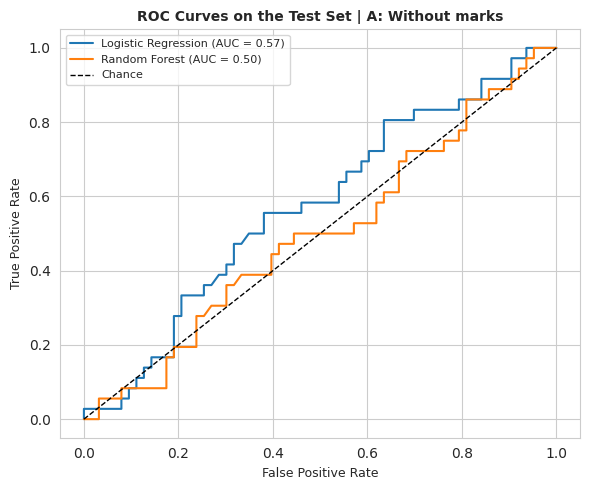

In [ ]:
plot_roc('A: Without marks')

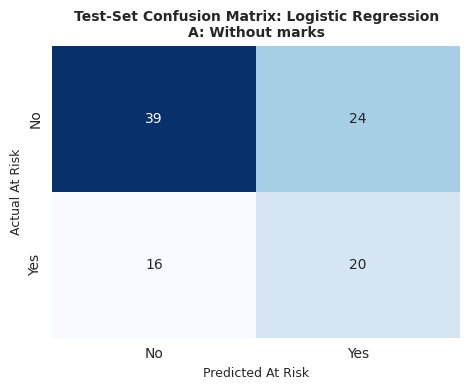

In [ ]:
plot_confusion('A: Without marks', 'Logistic Regression')

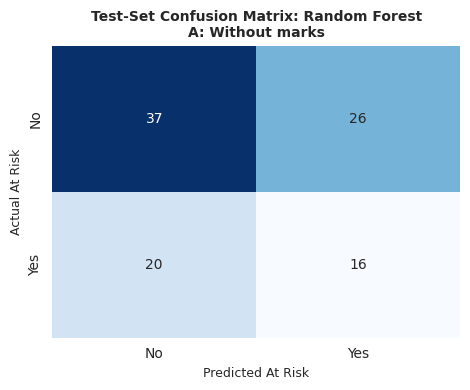

In [ ]:
plot_confusion('A: Without marks', 'Random Forest')

## 9.2 Random Forest feature importance

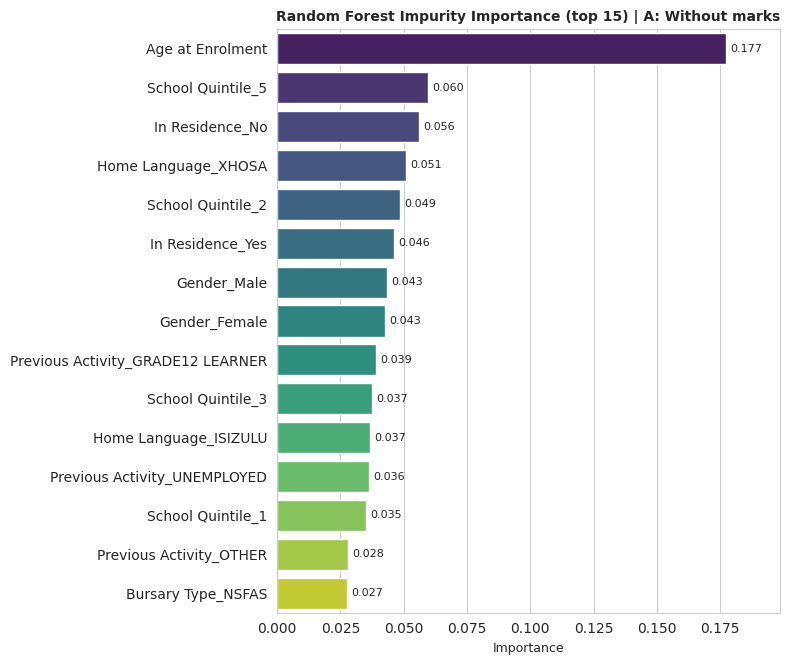

In [ ]:
imp_a = plot_impurity('A: Without marks')

In [ ]:
# Generate raw permutation importance manually to ensure a self-contained block
from sklearn.inspection import permutation_importance
import pandas as pd

perm_a = {}
for name in ['Logistic Regression', 'Random Forest']:
    r = permutation_importance(fitted['A: Without marks'][name], X_test['A: Without marks'], y_test, scoring='roc_auc',
                               n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1)
    perm_a[name] = pd.DataFrame({
        'Feature': X_test['A: Without marks'].columns,
        'Mean': r.importances_mean
    })

# Extract mean permutation importance for both models
rf_perm = perm_a['Random Forest'][['Feature', 'Mean']].rename(columns={'Mean': 'RF Permutation (ROC-AUC drop)'})
lr_perm = perm_a['Logistic Regression'][['Feature', 'Mean']].rename(columns={'Mean': 'LR Permutation (ROC-AUC drop)'})

# Get Random Forest impurity (Gini) importance from the trained model
pipe_rf = fitted['A: Without marks']['Random Forest']
rf_features = [n.split('__', 1)[1] for n in pipe_rf.named_steps['preprocessor'].get_feature_names_out()]
rf_gini_importances = pipe_rf.named_steps['model'].feature_importances_
gini_df = pd.DataFrame({'Feature': rf_features, 'RF Gini Importance': rf_gini_importances})

# Map one-hot encoded categories back to their primary variables or display them directly
# Since permutation is on raw columns and Gini is on preprocessed columns, we aggregate Gini by raw column names
raw_features = X_test['A: Without marks'].columns
gini_grouped = []
for col in raw_features:
    # Find all encoded features originating from this raw feature
    matching_vals = gini_df[gini_df['Feature'].str.startswith(col)]['RF Gini Importance'].sum()
    gini_grouped.append({'Feature': col, 'RF Gini (Impurity)': matching_vals})
gini_grouped_df = pd.DataFrame(gini_grouped)

# Merge all importance metrics into one summary table
summary_table = rf_perm.merge(gini_grouped_df, on='Feature').merge(lr_perm, on='Feature')
summary_table = summary_table.sort_values(by='RF Permutation (ROC-AUC drop)', ascending=False).reset_index(drop=True)

display(summary_table.round(4))

,Feature,RF Permutation (ROC-AUC drop),RF Gini (Impurity),LR Permutation (ROC-AUC drop)
0,School Quintile,0.0317,0.2070,0.0494
1,Bursary Type,0.0186,0.0587,0.0433
2,Previous Activity,0.0079,0.1142,0.0058
3,Ethnic Group,-0.0102,0.0218,-0.0177
4,Funded,-0.0118,0.0407,0.0029
5,Home Language,-0.0143,0.1657,0.0351
6,Matric Type,-0.0198,0.0262,-0.0279
7,Age at Enrolment,-0.0213,0.1774,0.0045
8,In Residence,-0.0243,0.1021,-0.0025
9,Gender,-0.0476,0.0862,-0.0049


# 10. Feature set B: with subject marks

## 10.1 Results

In [ ]:
print('=== Training-set cross-validation | B: With marks ===')
display(cv_results['B: With marks'].round(3))
print('\n=== Test set (30%) | B: With marks ===')
display(test_results['B: With marks'].round(3))

=== Training-set cross-validation | B: With marks ===


,Accuracy,Precision,Recall,F1-Score,ROC-AUC,ROC-AUC SD
Baseline (Majority),0.632,0.000,0.000,0.000,0.500,0.000
Logistic Regression,0.866,0.810,0.863,0.829,0.931,0.045
Random Forest,0.888,0.888,0.808,0.841,0.957,0.034



=== Test set (30%) | B: With marks ===


,Accuracy,Precision,Recall,F1-Score,ROC-AUC,AUC 95% CI low,AUC 95% CI high
Baseline (Majority),0.636,0.000,0.000,0.000,0.500,0.500,0.500
Logistic Regression,0.859,0.824,0.778,0.800,0.932,0.878,0.974
Random Forest,0.869,0.848,0.778,0.812,0.940,0.895,0.977


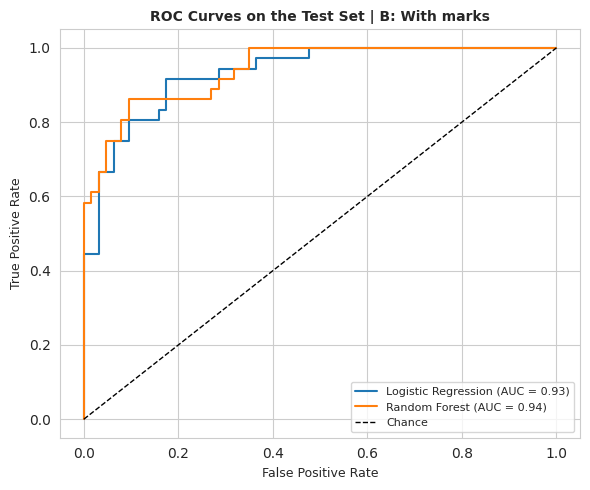

In [ ]:
plot_roc('B: With marks')

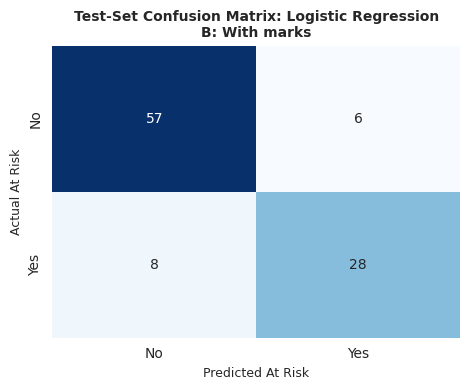

In [ ]:
plot_confusion('B: With marks', 'Logistic Regression')

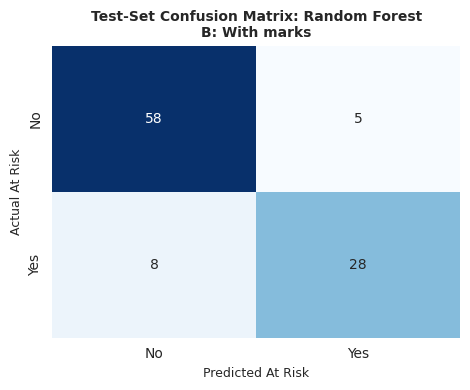

In [ ]:
plot_confusion('B: With marks', 'Random Forest')

## 10.2 Logistic Regression coefficients

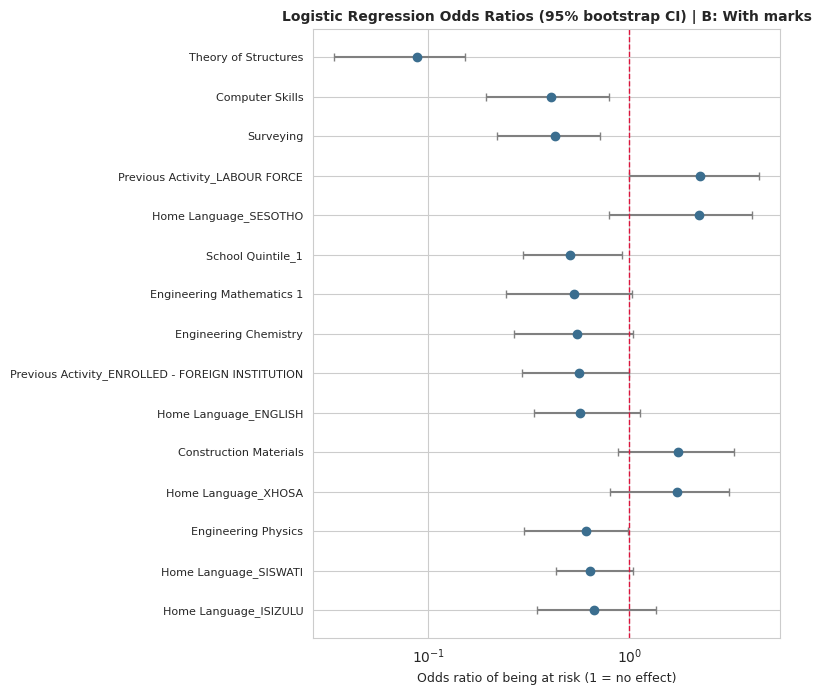

,Feature,Coefficient,Odds Ratio,OR 95% CI low,OR 95% CI high,CI excludes 1
0,Theory of Structures,-2.429,0.088,0.034,0.152,True
1,Computer Skills,-0.901,0.406,0.193,0.788,True
2,Surveying,-0.851,0.427,0.220,0.713,True
3,Previous Activity_LABOUR FORCE,0.808,2.242,1.000,4.389,False
4,Home Language_SESOTHO,0.800,2.226,0.796,4.047,False
5,School Quintile_1,-0.679,0.507,0.296,0.922,True
6,Engineering Mathematics 1,-0.638,0.528,0.245,1.033,False
7,Engineering Chemistry,-0.595,0.551,0.267,1.043,False
8,Previous Activity_ENROLLED - FOREIGN INSTITUTION,-0.580,0.560,0.292,1.000,False
9,Home Language_ENGLISH,-0.564,0.569,0.335,1.124,False


In [ ]:
coef_b = plot_coefficients('B: With marks')
display(coef_b.head(15).round(3))

## 10.3 Random Forest feature importance

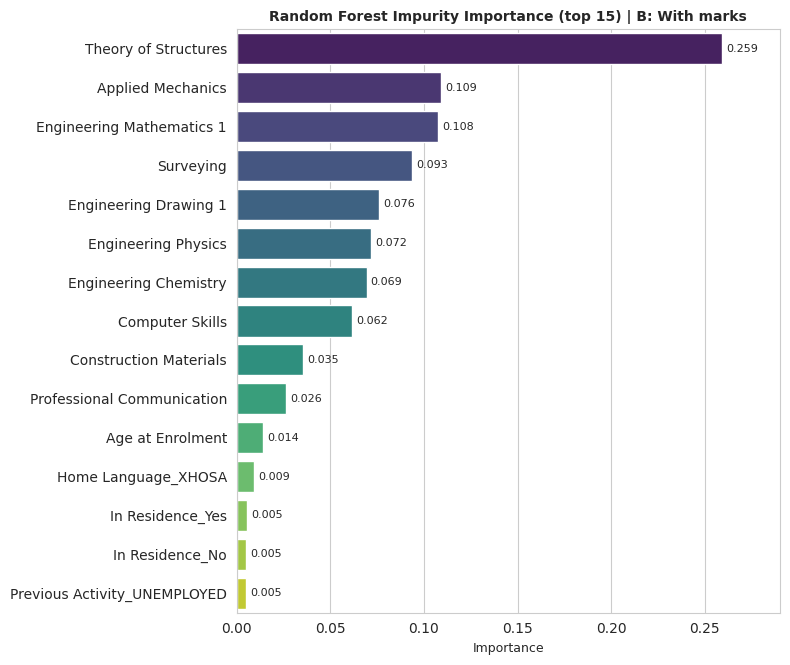

In [ ]:
imp_b = plot_impurity('B: With marks')

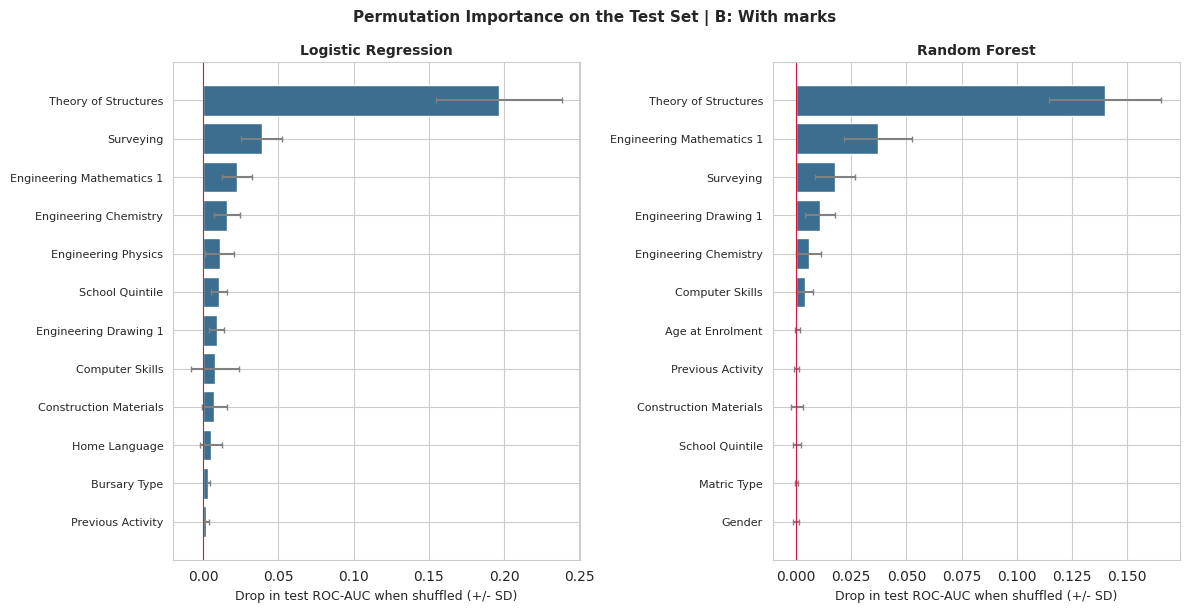

,Feature,Mean,Std
0,Theory of Structures,0.1401,0.0255
1,Engineering Mathematics 1,0.0371,0.0152
2,Surveying,0.0176,0.0090
3,Engineering Drawing 1,0.0109,0.0068
4,Engineering Chemistry,0.0057,0.0057
5,Computer Skills,0.0042,0.0037
6,Age at Enrolment,0.0005,0.0011
7,Previous Activity,0.0003,0.0012
8,Construction Materials,0.0003,0.0026
9,School Quintile,0.0002,0.0018


In [ ]:
perm_b = plot_permutation('B: With marks')
display(perm_b['Random Forest'].round(4))

# 11. Comparing the two feature sets

,Feature set,Model,CV ROC-AUC (train),Test ROC-AUC
0,A: Without marks,Logistic Regression,0.368,0.572
1,A: Without marks,Random Forest,0.527,0.497
2,B: With marks,Logistic Regression,0.931,0.932
3,B: With marks,Random Forest,0.957,0.940


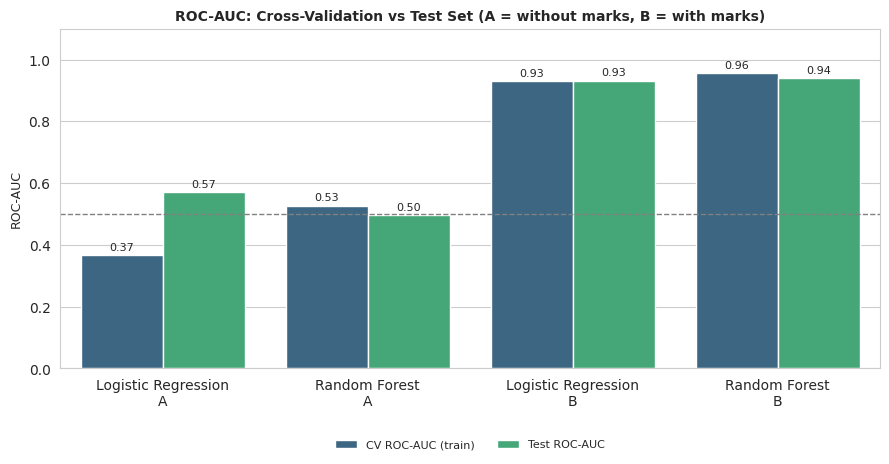

In [ ]:
# ROC-AUC: cross-validation (training set) versus test set, for both feature sets
rows = []
for label in feature_sets:
    for name in ['Logistic Regression', 'Random Forest']:
        rows.append({'Feature set': label, 'Model': name,
                     'CV ROC-AUC (train)': cv_results[label].loc[name, 'ROC-AUC'],
                     'Test ROC-AUC': test_results[label].loc[name, 'ROC-AUC']})
comparison = pd.DataFrame(rows)
display(comparison.round(3))

plot_df = comparison.melt(id_vars=['Feature set', 'Model'], var_name='Evaluation', value_name='ROC-AUC')
plot_df['Model and feature set'] = plot_df['Model'] + '\n' + plot_df['Feature set'].str[0]

plt.figure(figsize=(9, 4.8))
ax = sns.barplot(data=plot_df, x='Model and feature set', y='ROC-AUC', hue='Evaluation', palette='viridis')
add_bar_labels(ax, fmt='{:.2f}', fontsize=8)
ax.axhline(0.5, ls='--', color='grey', lw=1)
ax.set_ylim(0, 1.1)
plt.title('ROC-AUC: Cross-Validation vs Test Set (A = without marks, B = with marks)', fontsize=10, fontweight='bold')
plt.xlabel('')
plt.ylabel('ROC-AUC', fontsize=9)
plt.legend(fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=2, frameon=False)
plt.tight_layout()
plt.show()

In [ ]:
# Plain-language summary of the numbers above
for label in feature_sets:
    t = test_results[label].drop(index='Baseline (Majority)')
    best = t['ROC-AUC'].idxmax()
    print(f"{label}\n   best model on the test set: {best} | ROC-AUC = {t.loc[best, 'ROC-AUC']:.3f} "
          f"(95% CI {t.loc[best, 'AUC 95% CI low']:.3f} to {t.loc[best, 'AUC 95% CI high']:.3f}) | "
          f"recall = {t.loc[best, 'Recall']:.3f} | precision = {t.loc[best, 'Precision']:.3f}   (chance ROC-AUC = 0.500)")

A: Without marks
   best model on the test set: Logistic Regression | ROC-AUC = 0.572 (95% CI 0.453 to 0.695) | recall = 0.556 | precision = 0.455   (chance ROC-AUC = 0.500)
B: With marks
   best model on the test set: Random Forest | ROC-AUC = 0.940 (95% CI 0.895 to 0.977) | recall = 0.778 | precision = 0.848   (chance ROC-AUC = 0.500)


### 12. Hyperparameter Tuning

In [ ]:
from sklearn.model_selection import GridSearchCV

# Dictionary to hold the tuned estimators and results
tuned_fitted = {}
tuned_test_proba = {}
tuned_test_results = {}

# Define a more efficient parameter grid to ensure fast completion
param_grids = {
    'Logistic Regression': {
        'model__C': [0.1, 1.0, 10.0],
        'model__solver': ['liblinear']
    },
    'Random Forest': {
        'model__max_depth': [5, 8, None],
        'model__min_samples_split': [2, 5],
        'model__n_estimators': [100, 200]
    }
}

# Perform Grid Search CV for each feature set
for label in feature_sets:
    tuned_fitted[label] = {}
    tuned_test_proba[label] = {}
    rows = {}

    for name in ['Logistic Regression', 'Random Forest']:
        pipeline = make_pipeline(label, name)
        grid_search = GridSearchCV(
            estimator=pipeline,
            param_grid=param_grids[name],
            scoring='roc_auc',
            cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),  # 3-fold for speed
            n_jobs=-1
        )

        # Fit Grid Search on the training data
        grid_search.fit(X_train[label], y_train)
        best_model = grid_search.best_estimator_
        tuned_fitted[label][name] = best_model

        # Predict probabilities and classes on the test set
        proba = best_model.predict_proba(X_test[label])[:, 1]
        pred = (proba >= 0.5).astype(int)
        tuned_test_proba[label][name] = proba

        # Calculate bootstrap confidence intervals for ROC-AUC
        lo, hi = bootstrap_auc_ci(y_test, proba)

        # Gather performance metrics
        rows[name] = {
            'Best Params': str(grid_search.best_params_),
            'Accuracy': accuracy_score(y_test, pred),
            'Precision': precision_score(y_test, pred, zero_division=0),
            'Recall': recall_score(y_test, pred, zero_division=0),
            'F1-Score': f1_score(y_test, pred, zero_division=0),
            'ROC-AUC': roc_auc_score(y_test, proba),
            'AUC 95% CI low': lo,
            'AUC 95% CI high': hi
        }

    tuned_test_results[label] = pd.DataFrame(rows).T

### 12.1 Tuned Model Performance Tables

In [ ]:
for label in feature_sets:
    print(f"=== Tuned Model Summary: {label} (Test Set Evaluation) ===")
    display(tuned_test_results[label].round(3))
    print("\n")

=== Tuned Model Summary: A: Without marks (Test Set Evaluation) ===


,Best Params,Accuracy,Precision,Recall,F1-Score,ROC-AUC,AUC 95% CI low,AUC 95% CI high
Logistic Regression,"{'model__C': 0.1, 'model__solver': 'liblinear'}",0.585859,0.435897,0.472222,0.453333,0.601411,0.483471,0.720538
Random Forest,"{'model__max_depth': None, 'model__min_samples...",0.545455,0.395349,0.472222,0.43038,0.507496,0.388005,0.632583




=== Tuned Model Summary: B: With marks (Test Set Evaluation) ===


,Best Params,Accuracy,Precision,Recall,F1-Score,ROC-AUC,AUC 95% CI low,AUC 95% CI high
Logistic Regression,"{'model__C': 0.1, 'model__solver': 'liblinear'}",0.808081,0.72973,0.75,0.739726,0.914903,0.856812,0.961538
Random Forest,"{'model__max_depth': None, 'model__min_samples...",0.858586,0.84375,0.75,0.794118,0.943122,0.898752,0.979193


### 13. Model Summaries

In [ ]:
import pandas as pd

def get_summary_row(results_df, model_name, row_label):
    row = results_df.loc[model_name].copy()
    row.name = row_label
    return pd.DataFrame(row).T

# Logistic Regression Summary Table
lr_summary = pd.concat([
    get_summary_row(test_results['A: Without marks'], 'Logistic Regression', 'Without Marks (Set A)'),
    get_summary_row(test_results['B: With marks'], 'Logistic Regression', 'With Marks (Set B)'),
    get_summary_row(tuned_test_results['B: With marks'], 'Logistic Regression', 'Tuned With Marks (Set B)')
])
lr_summary.index.name = 'Scenario'

# Random Forest Summary Table
rf_summary = pd.concat([
    get_summary_row(test_results['A: Without marks'], 'Random Forest', 'Without Marks (Set A)'),
    get_summary_row(test_results['B: With marks'], 'Random Forest', 'With Marks (Set B)'),
    get_summary_row(tuned_test_results['B: With marks'], 'Random Forest', 'Tuned With Marks (Set B)')
])
rf_summary.index.name = 'Scenario'

print(" LOGISTIC REGRESSION SUMMARY")
display(lr_summary.round(3))
print("\n RANDOM FOREST SUMMARY")
display(rf_summary.round(3))

 LOGISTIC REGRESSION SUMMARY


,Accuracy,Precision,Recall,F1-Score,ROC-AUC,AUC 95% CI low,AUC 95% CI high,Best Params
Scenario,,,,,,,,
Without Marks (Set A),0.59596,0.454545,0.555556,0.5,0.571869,0.45338,0.694724,NaN
With Marks (Set B),0.858586,0.823529,0.777778,0.8,0.932099,0.878123,0.973948,NaN
Tuned With Marks (Set B),0.808081,0.72973,0.75,0.739726,0.914903,0.856812,0.961538,"{'model__C': 0.1, 'model__solver': 'liblinear'}"



 RANDOM FOREST SUMMARY


,Accuracy,Precision,Recall,F1-Score,ROC-AUC,AUC 95% CI low,AUC 95% CI high,Best Params
Scenario,,,,,,,,
Without Marks (Set A),0.535354,0.380952,0.444444,0.410256,0.497354,0.376137,0.618985,NaN
With Marks (Set B),0.868687,0.848485,0.777778,0.811594,0.940476,0.895037,0.977388,NaN
Tuned With Marks (Set B),0.858586,0.84375,0.75,0.794118,0.943122,0.898752,0.979193,"{'model__max_depth': None, 'model__min_samples..."


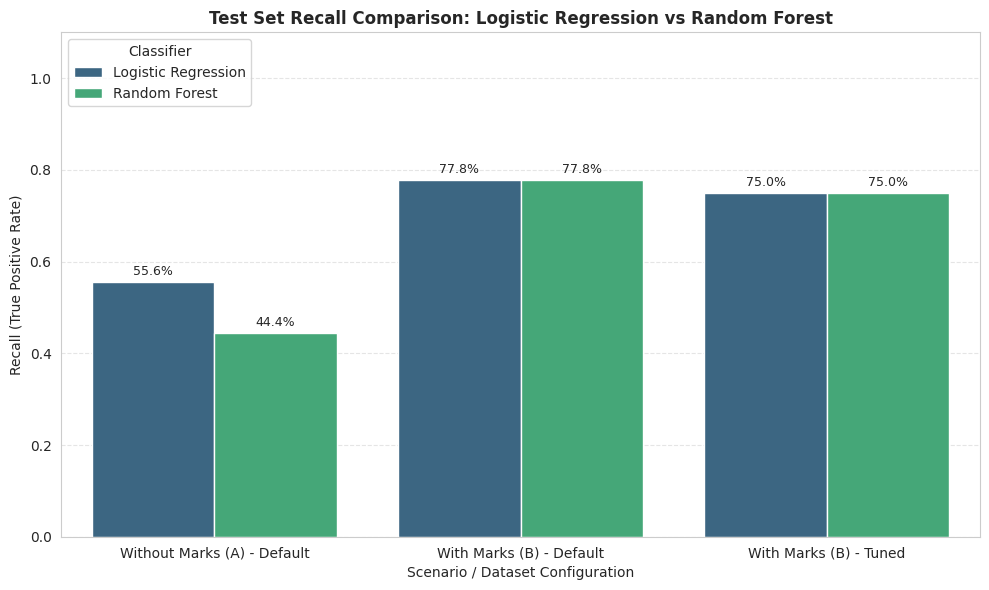

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Gather Recall values from our previous tables
recall_data = []

# Feature Set A Default
for model_name in ['Logistic Regression', 'Random Forest']:
    recall_data.append({
        'Model': model_name,
        'Scenario': 'Without Marks (A) - Default',
        'Recall': test_results['A: Without marks'].loc[model_name, 'Recall']
    })

# Feature Set B Default
for model_name in ['Logistic Regression', 'Random Forest']:
    recall_data.append({
        'Model': model_name,
        'Scenario': 'With Marks (B) - Default',
        'Recall': test_results['B: With marks'].loc[model_name, 'Recall']
    })

# Feature Set B Tuned
for model_name in ['Logistic Regression', 'Random Forest']:
    recall_data.append({
        'Model': model_name,
        'Scenario': 'With Marks (B) - Tuned',
        'Recall': tuned_test_results['B: With marks'].loc[model_name, 'Recall']
    })

recall_df = pd.DataFrame(recall_data)

# Plotting
plt.figure(figsize=(10, 6))
ax = sns.barplot(data=recall_df, x='Scenario', y='Recall', hue='Model', palette='viridis')

# Annotate bar values
for p in ax.patches:
    height = p.get_height()
    if pd.notna(height) and height > 0:
        ax.annotate(f'{height:.1%}',
                    (p.get_x() + p.get_width() / 2, height),
                    ha='center', va='bottom', fontsize=9,
                    xytext=(0, 3), textcoords='offset points')

plt.title('Test Set Recall Comparison: Logistic Regression vs Random Forest', fontsize=12, fontweight='bold')
plt.xlabel('Scenario / Dataset Configuration', fontsize=10)
plt.ylabel('Recall (True Positive Rate)', fontsize=10)
plt.ylim(0, 1.1)
plt.legend(title='Classifier', loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

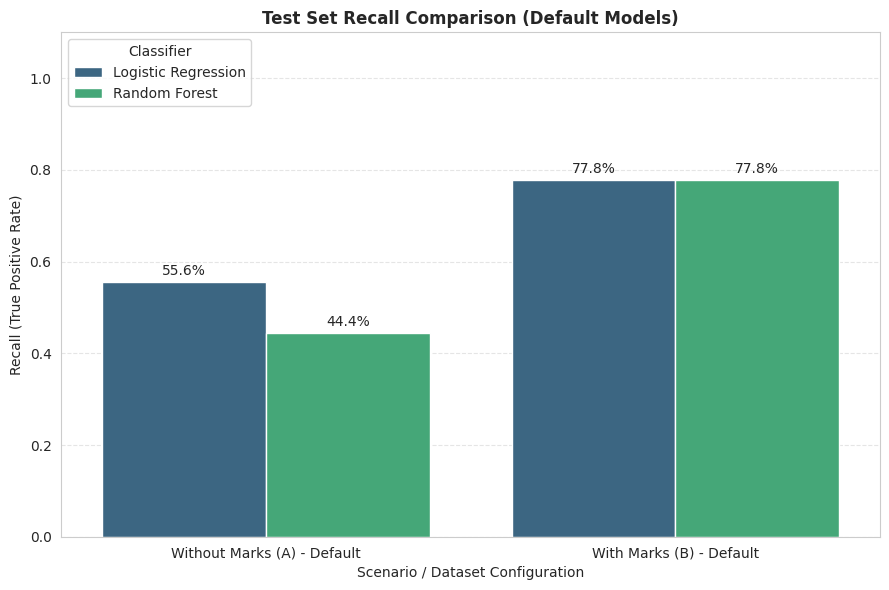

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Gather only default Recall values
recall_default_data = []

# Feature Set A Default
for model_name in ['Logistic Regression', 'Random Forest']:
    recall_default_data.append({
        'Model': model_name,
        'Scenario': 'Without Marks (A) - Default',
        'Recall': test_results['A: Without marks'].loc[model_name, 'Recall']
    })

# Feature Set B Default
for model_name in ['Logistic Regression', 'Random Forest']:
    recall_default_data.append({
        'Model': model_name,
        'Scenario': 'With Marks (B) - Default',
        'Recall': test_results['B: With marks'].loc[model_name, 'Recall']
    })

recall_default_df = pd.DataFrame(recall_default_data)

# Plotting
plt.figure(figsize=(9, 6))
ax = sns.barplot(data=recall_default_df, x='Scenario', y='Recall', hue='Model', palette='viridis')

# Annotate bar values
for p in ax.patches:
    height = p.get_height()
    if pd.notna(height) and height > 0:
        ax.annotate(f'{height:.1%}',
                    (p.get_x() + p.get_width() / 2, height),
                    ha='center', va='bottom', fontsize=10,
                    xytext=(0, 3), textcoords='offset points')

plt.title('Test Set Recall Comparison (Default Models)', fontsize=12, fontweight='bold')
plt.xlabel('Scenario / Dataset Configuration', fontsize=10)
plt.ylabel('Recall (True Positive Rate)', fontsize=10)
plt.ylim(0, 1.1)
plt.legend(title='Classifier', loc='upper left')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()